##### Recherche du minimum

In [1]:
from algo.neldermead import NelderMead, init_simplex
from utils.point import Point

def f(p: Point)->float:
    x0 = p[0]
    x1 = p[1]
    x2 = p[2]
    x3 = p[3]

    return (x0 + 10*x1)**2 + 5*(x2 - x3)**2 + (x1 - 2*x2)**4 + 10*(x0 - x3)**4

n_itr = 2000
epsilon = 10**-8

best_values = []
history_step = []

times = []
avg_times = []

for i in range(10):
    simplex = init_simplex([3, -1, 0, 1], 5)
    algo = NelderMead(
        simplex,
        f,
        scalaire_reflexion=1,
        scalaire_expansion=2,
        scalaire_contraction=0.5,
        scalaire_homothetie=0.5
    )
    algo.compute(n_itr)

    best_point = algo.history_benchmark["best_points"][-1]
    best_value = algo.history_benchmark["best_values"][-1]

    best_values = [v for v in algo.history_benchmark["best_values"] if v > epsilon]

    history_step = [v for v in algo.history if v["step"] < len(best_values) ]

    if i == 0:
        print("Meilleur point:", best_point)
        print("Valeur du meilleur point:", best_value)
        print("Itération avant convergence:", len(best_values))

    __times = algo.history_benchmark["execution_time"]
    _times = [__times[i] for i in range(len(best_values))]
    times.append(sum(_times))
    avg_times.append(sum(_times) / len(_times))

print("Temps d'exécution:", sum(times) / len(times), "ns")
print("Temps d'exécution moyens par itr: ", sum(avg_times) / len(avg_times), "ns")


Meilleur point: Point([1.031606019066808e-16, -1.031606019066808e-17, 4.476742978261429e-17, 4.476742978261429e-17], Dimension: 4)
Valeur du meilleur point: 2.156698177162151e-64
Itération avant convergence: 144
Temps d'exécution: 2383400.0 ns
Temps d'exécution moyens par itr:  16551.388888888887 ns


##### Convergence de la fonction

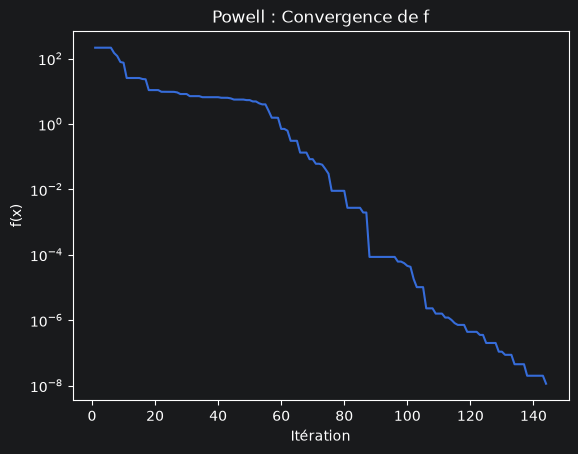

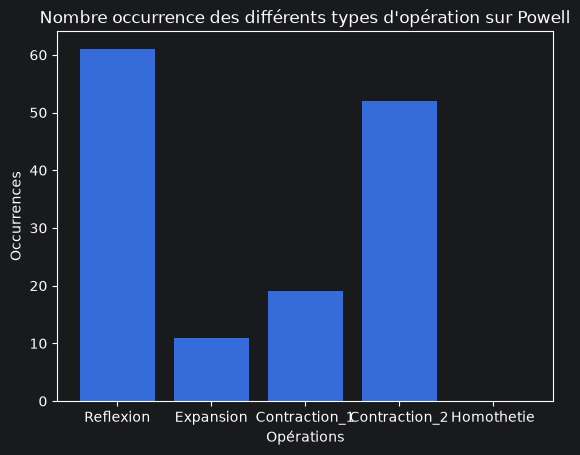

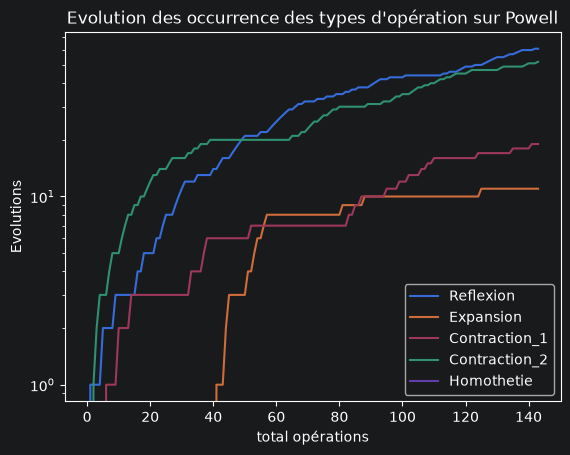

In [2]:
from benchmark.benchmark_utils import *

graph_convergence(best_values, "Powell")
graph_nelder_mead_type_operation(history_step, "Powell")
graph_nelder_mead_type_2(history_step, "Powell")